In [43]:
# Libraries

RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
%load_ext autoreload
%autoreload 2

import sys
import math
from pathlib import Path

import torch
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.tokenizer import CharTokenizer
from src.dataset import get_batch
from src.model import BigramLanguageModel
from src.training import train_model
from src.evaluation import calculate_perplexity
from src.generation import generate

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [44]:
# Loading

# Data

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"


def load_tensor(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )
    except TypeError:
        return torch.load(
            path,
            map_location="cpu"
        )


train_data = load_tensor(PROCESSED_DIR / "train.pt")
val_data = load_tensor(PROCESSED_DIR / "val.pt")
test_data = load_tensor(PROCESSED_DIR / "test.pt")


print("Train tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Test tokens:", len(test_data))

# Tokenizer

import json

with open(
    PROCESSED_DIR / "tokenizer.json",
    "r",
    encoding="utf-8"
) as file:

    tokenizer_state = json.load(file)

tokenizer = CharTokenizer.from_dict(tokenizer_state)

vocab_size = tokenizer.vocab_size

print("Vocabulary size:", vocab_size)
print("Vocabulary:", repr("".join(tokenizer.chars)))

Train tokens: 1003854
Validation tokens: 55770
Test tokens: 55770
Vocabulary size: 65
Vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"


In [45]:
# Inspection

block_size = 64
batch_size = 32

device = "cuda" if torch.cuda.is_available() else "cpu"

x, y = get_batch(
    train_data,
    batch_size=batch_size,
    block_size=block_size,
    device=device
)

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nInput:")
print(tokenizer.decode(x[0].cpu().tolist()))

print("\nTarget:")
print(tokenizer.decode(y[0].cpu().tolist()))

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])

Input:
ay you, let's to him.

CORIOLANUS:
Let them puff all about mine 

Target:
y you, let's to him.

CORIOLANUS:
Let them puff all about mine e


In [46]:
# Initialization

torch.manual_seed(42)

model = BigramLanguageModel(
    vocab_size=vocab_size
).to(device)

print(model)

num_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nNumber of parameters:", num_parameters)

BigramLanguageModel(
  (token_embedding_table): Embedding(65, 65)
)

Number of parameters: 4225


In [47]:
# Biagram training

max_iters = 2000
eval_interval = 100
eval_iters = 10

learning_rate = 1e-2
weight_decay = 1e-4

history = train_model(
    model=model,
    train_data=train_data,
    val_data=val_data,

    max_iters=max_iters,

    batch_size=batch_size,
    block_size=block_size,

    learning_rate=learning_rate,
    weight_decay=weight_decay,

    eval_interval=eval_interval,
    eval_iters=eval_iters,

    grad_clip=1.0,
    device=device
)

Step     1 | Train Loss: 4.7355 | Val Loss: 4.7551
Step   100 | Train Loss: 3.6078 | Val Loss: 3.6390
Step   200 | Train Loss: 2.9912 | Val Loss: 3.0112
Step   300 | Train Loss: 2.6952 | Val Loss: 2.7177
Step   400 | Train Loss: 2.5853 | Val Loss: 2.5928
Step   500 | Train Loss: 2.5300 | Val Loss: 2.5558
Step   600 | Train Loss: 2.5084 | Val Loss: 2.5102
Step   700 | Train Loss: 2.4928 | Val Loss: 2.5018
Step   800 | Train Loss: 2.4997 | Val Loss: 2.4899
Step   900 | Train Loss: 2.4842 | Val Loss: 2.4958
Step  1000 | Train Loss: 2.4858 | Val Loss: 2.4970
Step  1100 | Train Loss: 2.4758 | Val Loss: 2.4878
Step  1200 | Train Loss: 2.4502 | Val Loss: 2.4905
Step  1300 | Train Loss: 2.4900 | Val Loss: 2.4917
Step  1400 | Train Loss: 2.4632 | Val Loss: 2.4879
Step  1500 | Train Loss: 2.4724 | Val Loss: 2.4969
Step  1600 | Train Loss: 2.4656 | Val Loss: 2.4866
Step  1700 | Train Loss: 2.4607 | Val Loss: 2.4823
Step  1800 | Train Loss: 2.4646 | Val Loss: 2.4745
Step  1900 | Train Loss: 2.4457

,step,train_loss,val_loss
16,1600,2.465554,2.486562
17,1700,2.460713,2.482330
18,1800,2.464632,2.474517
19,1900,2.445693,2.485486
20,2000,2.453916,2.486051


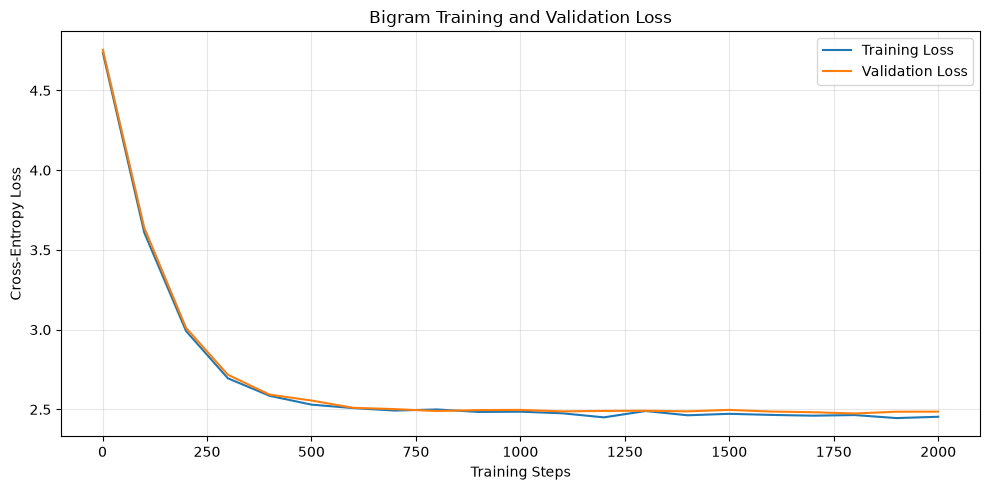

In [48]:
# Visualization

history_df = pd.DataFrame(history)

display(history_df.tail())

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["step"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["step"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")

plt.title("Bigram Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures"
    / "bigram_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
# Evaluate on test set

@torch.no_grad()
def evaluate_test(model, data, block_size, device):

    was_training = model.training
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for start in range(0, len(data) - 1, block_size):

        # Ensure input and target have the same length
        end = min(
            start + block_size,
            len(data) - 1
        )

        x = data[start:end]
        y = data[start + 1:end + 1]

        if len(x) == 0:
            continue

        x = x.unsqueeze(0).to(device)
        y = y.unsqueeze(0).to(device)

        _, loss = model(x, y)

        num_tokens = y.numel()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    model.train(was_training)

    return total_loss / total_tokens

test_loss = evaluate_test(
    model=model,
    data=test_data,
    block_size=block_size,
    device=device
)

test_perplexity = calculate_perplexity(test_loss)

print("Test Loss:", round(test_loss, 4))
print("Test Perplexity:", round(test_perplexity, 4))

Test Loss: 2.4981
Test Perplexity: 12.1589


In [50]:
# Analysis

current_char = " "

current_id = tokenizer.stoi[current_char]

with torch.no_grad():

    logits = model.token_embedding_table.weight[
        current_id
    ]

    probabilities = F.softmax(
        logits,
        dim=-1
    )

top_probs, top_ids = torch.topk(
    probabilities,
    k=10
)

results = pd.DataFrame({
    "Next Character": [
        repr(tokenizer.itos[index.item()])
        for index in top_ids
    ],

    "Probability": top_probs.numpy()
})

display(results)


,Next Character,Probability
0,'t',0.142902
1,'a',0.081304
2,'s',0.070120
3,'h',0.069217
4,'w',0.063098
5,'m',0.062536
6,'b',0.051410
7,'o',0.041445
8,'i',0.041188
9,'f',0.037129


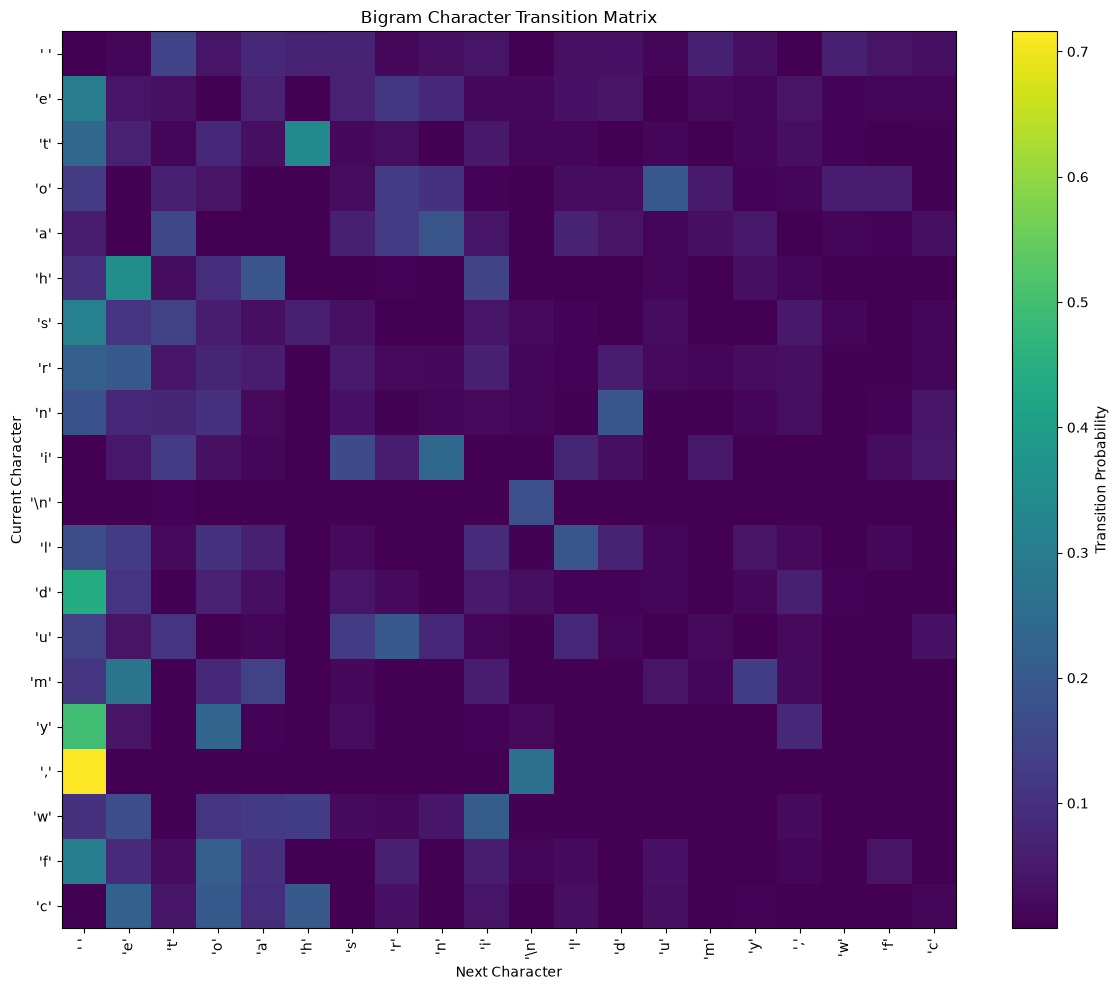

In [51]:
# Character transition

with torch.no_grad():

    transition_probs = F.softmax(
        model.token_embedding_table.weight,
        dim=-1
    ).cpu().numpy()


char_counts = torch.bincount(
    train_data,
    minlength=vocab_size
)

top_char_ids = torch.topk(
    char_counts,
    k=min(20, vocab_size)
).indices.tolist()

selected_probs = transition_probs[
    np.ix_(top_char_ids, top_char_ids)
]

labels = [
    repr(tokenizer.itos[index])
    for index in top_char_ids
]

plt.figure(figsize=(12, 10))

plt.imshow(
    selected_probs,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Transition Probability")

plt.xticks(
    range(len(labels)),
    labels,
    rotation=90
)

plt.yticks(
    range(len(labels)),
    labels
)

plt.xlabel("Next Character")
plt.ylabel("Current Character")

plt.title("Bigram Character Transition Matrix")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures"
    / "bigram_transition_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
# Generation

prompt = "ROMEO:\n"

prompt_ids = tokenizer.encode(prompt)

idx = torch.tensor(
    [prompt_ids],
    dtype=torch.long,
    device=device
)

generated_ids = generate(
    model=model,
    idx=idx,

    max_new_tokens=500,

    block_size=block_size,

    temperature=0.8,
    top_k=20
)

generated_text = tokenizer.decode(
    generated_ids[0].cpu().tolist()
)

print(generated_text)

ROMEO:
Thely as,
Ane thavigherome brda fofatrdeaikigond and y, s an illo bonthensof ineand ouisel f hanof wh th, s.
ARELOMI y ors tans hathatar pofangalve llisal se hene
GI th's! icineth har in nest mou wis youlo ds stemy yothe re we myourdso lt ithe e s,


Ifowhasesoumstoushenofenspes br pse st, ba g ist d, has hat
Cot'st my: ie ing ther be she ll two ton g me oss ar len son the s tre the t sefathaksteimad I or ove anen t wit a inos sthe, borea sem toren m l t y men my ger,
BENUMato beaval t g akndin 


In [53]:
# Experiment

prompts = [
    "ROMEO:",
    "JULIET:"
]

for prompt in prompts:

    prompt_ids = tokenizer.encode(prompt)

    idx = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    generated_ids = generate(
        model=model,
        idx=idx,
        max_new_tokens=100,
        block_size=block_size,
        temperature=0.8,
        top_k=20
    )

    print("=" * 50)
    print("Prompt:", prompt)
    print(tokenizer.decode(generated_ids[0].cpu().tolist()))

Prompt: ROMEO:
ROMEO: mimes hasthilongnd r a thayorathee au ffarinerey weres, an ber f ng ougs lourove ang'lle, w hers fa
Prompt: JULIET:
JULIET:
Whis;
Thanofans tee h s at bul wh sthe sessted tandond chtor t frd sse alithese,
Hetortan thous tit


In [54]:
# Save results

prompts = [
    "ROMEO:",
    "JULIET:"
]

for prompt in prompts:

    prompt_ids = tokenizer.encode(prompt)

    idx = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    generated_ids = generate(
        model=model,
        idx=idx,
        max_new_tokens=100,
        block_size=block_size,
        temperature=0.8,
        top_k=20
    )

    print("=" * 50)
    print("Prompt:", prompt)
    print(tokenizer.decode(generated_ids[0].cpu().tolist()))

# Metrics
metrics = {
    "Model": "Bigram",
    "Parameters": num_parameters,
    "Test Loss": test_loss,
    "Test Perplexity": test_perplexity
}

metrics_df = pd.DataFrame([metrics])

display(metrics_df)

metrics_df.to_csv(
    RESULTS_DIR / "bigram_baseline_metrics.csv",
    index=False
)

# Checkpoints

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

torch.save(
    {
        "model_state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },

        "vocab_size": vocab_size,

        "tokenizer": tokenizer.to_dict(),

        "test_loss": test_loss,

        "test_perplexity": test_perplexity
    },

    CHECKPOINT_DIR / "bigram_baseline.pt"
)

print("Bigram checkpoint saved!")

Prompt: ROMEO:
ROMEO:
O:
A e brosere.
D wro ferk hais blin at iono rou the set ingo nd be ashe thispik fas wlone y ber th
Prompt: JULIET:
JULIET:
F fontesilomy INu wand; mourn int ye fou s t
ARCod agearn my

A:
Gouriss,

Whord f blo rseld oourea


,Model,Parameters,Test Loss,Test Perplexity
0,Bigram,4225,2.498061,12.158892


Bigram checkpoint saved!
